# PathSnap model 01: Logistic Regression

*Family: Linear / probabilistic*

**What every model in this project does.** For each GPS fix we already have a short list of *candidate* road arcs
(all arcs within 50 m, at least 5). Each (fix, candidate) pair is one row with 13 features (distance, heading
difference, …) and a label `y` = 1 if the candidate is the fix's true arc, else 0. The model learns
**P(candidate is the true arc | features)**. For each fix, the candidate with the highest probability is the
prediction. Every model notebook uses the same data, folds and metrics from `pathsnap_common.py`, so the numbers are
directly comparable.

**Metrics used below** (full definitions in the report):
- **Top-1 accuracy** (primary): share of fixes whose highest-probability candidate is the true arc.
- **Macro F1**: per trip, the F1-score of each road arc treated as a class, averaged over arcs (so short, rarely
  visited arcs count as much as long ones), then averaged over trips.
- **Log loss**: how good the probabilities are (lower is better); punishes confident mistakes.
- **Precision / recall / F1 / confusion matrix**: candidate level, "is this the true arc?" with threshold 0.5.
- **Route continuity**: share of consecutive fixes whose predicted arcs are the same or connected within 3 arcs.
- **Route F1**: length-weighted overlap between the set of predicted arcs and the reference route.

## 1. What the algorithm does

**Logistic regression** adds up the features, each multiplied by a learned weight, and squashes the sum through the
logistic (sigmoid) function to get a probability between 0 and 1:
P(true arc) = 1 / (1 + e<sup>−(w·x + b)</sup>). The decision boundary is a straight line (a flat plane) in feature
space.

## 2. Why we tried it for PathSnap, strengths and limitations

- It is the simplest model that outputs **probabilities**, which the HMM decoder later needs as emission scores.
- Two of our strongest features (`heading_diff`, `dist_gap`) have a roughly monotone effect: smaller is more likely
  to be the true arc. A linear model can capture that directly, so it is a strong, interpretable baseline.
- **Strengths:** very fast to train and predict, few hyperparameters, weights are interpretable, usually
  well-calibrated probabilities.
- **Limitations:** it cannot model interactions (e.g. heading matters only when the car is moving; distance matters
  less on roads with a twin) unless we hand-craft them. Effects that are not monotone (e.g. `along_t` near 0 or 1)
  are lost.

### Hyperparameters (initial values) and training objective

| Hyperparameter | Initial value | Meaning |
|---|---|---|
| `C` | 1.0 | inverse strength of the L2 penalty (smaller = simpler model) |
| `penalty` | L2 | shrinks weights towards 0 to avoid overfitting |
| `solver` | lbfgs | quasi-Newton optimiser |
| `max_iter` | 500 | iteration cap for the optimiser |
| preprocessing | log1p + standardise, one-hot `conn_prev` | puts features on comparable scales |
| `FRAC` | 0.4 | share of training fixes used per fit (≈ 580 k rows per CV fold) |


**Loss:** binary cross-entropy (= log loss) plus an L2 penalty ½‖w‖²/C, minimised with L-BFGS.

### Setup: load the candidate tables

In [1]:
import sys, time, json
sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathsnap_common import *

train = load_partition("train")          # every candidate row of the 80 train trips
test = load_partition("student_test")    # every candidate row of the 10 student_test trips
print(f"train: {len(train):,} rows ({train.keep_train.sum():,} with reliable labels) | student_test: {len(test):,} rows")
print("features:", FEATURES)

train: 2,103,209 rows (1,801,387 with reliable labels) | student_test: 222,004 rows
features: ['dist', 'dist_rank', 'dist_gap', 'heading_diff', 'speed', 'along_t', 'arc_len', 'has_twin', 'junction_deg', 'n_cand20', 'n_cand50', 'nbr_dist', 'conn_prev']


### Model definition

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

NAME, TITLE, FAMILY = "logistic_regression", "Logistic Regression", "Linear / probabilistic"
FRAC, SAVE_MODEL = 0.4, True
CONFIG = dict(C=1.0, penalty="l2", solver="lbfgs", max_iter=500, preprocessing="log1p+standardise, one-hot conn_prev",
              train_frac=FRAC)


def make_model():
    return make_pipeline(scaled_preprocessor(), LogisticRegression(C=1.0, solver="lbfgs", max_iter=500))

## 3. Cross-validation (GroupKFold by trip, 5 folds)

The 80 train trips are split into 5 groups of 16. Each fold trains on 64 trips and predicts the 16 held-out trips,
so the model is always scored on trips it has never seen (fixes of one trip are nearly identical, so mixing them
would inflate scores). Training uses a random `FRAC` share of the reliable-label fixes of the 64 trips (all
candidates of a chosen fix stay together); prediction covers every candidate of the held-out trips.
We also score the model on (a sample of) the fixes it was trained on: a large train/validation gap means
**overfitting**; low scores on both mean **underfitting**.

[logistic_regression] fold 1: train top-1 0.8584 | val top-1 0.8539 | val log loss 0.1014 | fit 3s


[logistic_regression] fold 2: train top-1 0.8529 | val top-1 0.8837 | val log loss 0.0791 | fit 3s


[logistic_regression] fold 3: train top-1 0.8651 | val top-1 0.8458 | val log loss 0.0911 | fit 3s


[logistic_regression] fold 4: train top-1 0.8517 | val top-1 0.9020 | val log loss 0.0667 | fit 3s


[logistic_regression] fold 5: train top-1 0.8676 | val top-1 0.8246 | val log loss 0.1081 | fit 3s


CV done in 27 s


,fold,train_rows,fit_s,train_top1,val_top1,train_logloss,val_logloss,val_macro_f1,val_precision,val_recall,val_f1,val_continuity,val_route_f1
0,1,576525,2.7209,0.8584,0.8539,0.0864,0.1014,0.6681,0.8503,0.7948,0.8216,0.9520,0.8337
1,2,579422,2.5381,0.8529,0.8837,0.0916,0.0791,0.7594,0.8525,0.8338,0.8430,0.9390,0.8917
2,3,574769,2.8147,0.8652,0.8458,0.0881,0.0911,0.6912,0.8428,0.7918,0.8165,0.9686,0.8528
3,4,575011,2.8336,0.8517,0.9020,0.0939,0.0667,0.7643,0.8744,0.8551,0.8647,0.9690,0.8957
4,5,575532,3.0157,0.8676,0.8246,0.0851,0.1081,0.6621,0.8125,0.8040,0.8082,0.9766,0.8201


mean ± std  val top-1 86.20% ± 3.08% | val macro F1 0.7090 ± 0.0495 | val log loss 0.0893


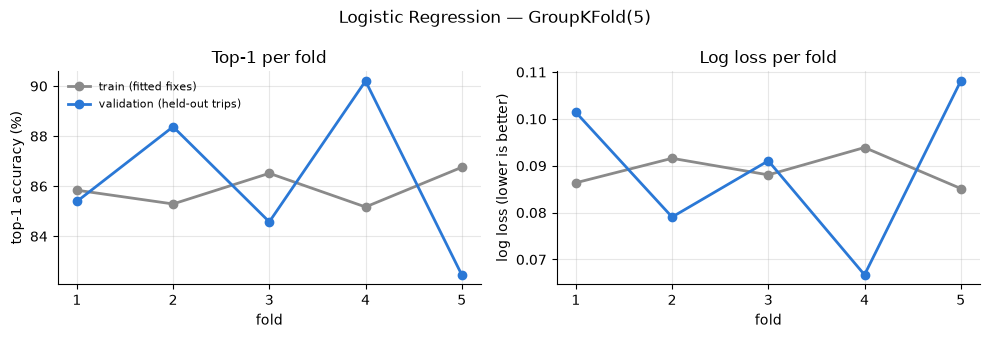

In [3]:
t0 = time.time()
cv, oof, cv_models = run_cv(make_model, train, FRAC, label=NAME)
print(f"CV done in {time.time() - t0:.0f} s")
show = ["fold", "train_rows", "fit_s", "train_top1", "val_top1", "train_logloss", "val_logloss", "val_macro_f1",
        "val_precision", "val_recall", "val_f1", "val_continuity", "val_route_f1"]
display(cv[show].round(4))
print("mean ± std  val top-1 {:.2%} ± {:.2%} | val macro F1 {:.4f} ± {:.4f} | val log loss {:.4f}".format(
    cv.val_top1.mean(), cv.val_top1.std(), cv.val_macro_f1.mean(), cv.val_macro_f1.std(), cv.val_logloss.mean()))
fig = plot_cv(cv, TITLE + " — GroupKFold(5)")
(OUT_DIR / NAME).mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / NAME / "fig_cv.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Final fit on all 80 train trips and evaluation on student_test

Refit with the same recipe on the reliable-label fixes of all 80 train trips, then score every candidate of the 10
student_test trips. student_test is used only for this development-stage comparison, never for training.
**Inference time** is the time `predict_proba` takes for all student_test candidates, per 1 000 GPS fixes
(features are already computed; feature building is the same for every model).

,student_test
top1,0.8708
top1_all,0.8368
macro_f1,0.7229
logloss,0.0746
precision,0.8485
recall,0.8450
f1,0.8468
continuity,0.9695
route_f1,0.8968
fit_s,3.2217


,trip,n_fix,top1,macro_f1,continuity,route_f1
0,00000000,2503,0.9353,0.6946,0.9836,0.9430
1,00000007,1354,0.9711,0.9274,0.9970,0.9837
2,00000009,1049,0.8341,0.7342,0.9590,0.8680
3,00000040,2995,0.9341,0.7732,0.9903,0.9241
4,00000052,262,0.9542,0.8173,0.9808,0.9472
5,00000056,3958,0.8802,0.7734,0.9292,0.9046
6,00000065,768,0.8268,0.6668,0.9687,0.8653
7,00000076,1486,0.8365,0.5701,0.9455,0.8416
8,00000077,3911,0.7436,0.5536,0.9895,0.7802
9,00000091,874,0.8410,0.7189,0.9588,0.9105


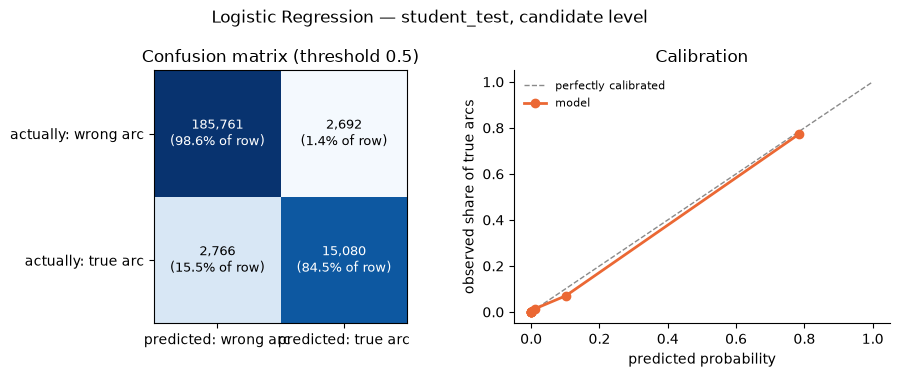

In [4]:
final_model, p_test, test_res, test_preds = fit_and_test(make_model, train, test, FRAC)
keys = ["top1", "top1_all", "macro_f1", "logloss", "precision", "recall", "f1", "continuity", "route_f1",
        "fit_s", "predict_ms_per_1k_fixes"]
display(pd.Series({k: test_res[k] for k in keys}).to_frame("student_test").round(4))
display(pd.DataFrame(test_res["per_trip"]).assign(trip=lambda d: [trips("student_test")[t] for t in d.tidx])
        .assign(top1=lambda d: d.correct_kept / d.n_kept)[["trip", "n_fix", "top1", "macro_f1", "continuity", "route_f1"]].round(4))
fig = plot_confusion_and_calibration(test, p_test, TITLE)
fig.savefig(OUT_DIR / NAME / "fig_confusion_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. What did the model learn? (coefficients)

Because the inputs are standardised, the size of a coefficient shows how strongly a feature moves the log-odds.
Negative = larger value makes the candidate *less* likely to be the true arc.

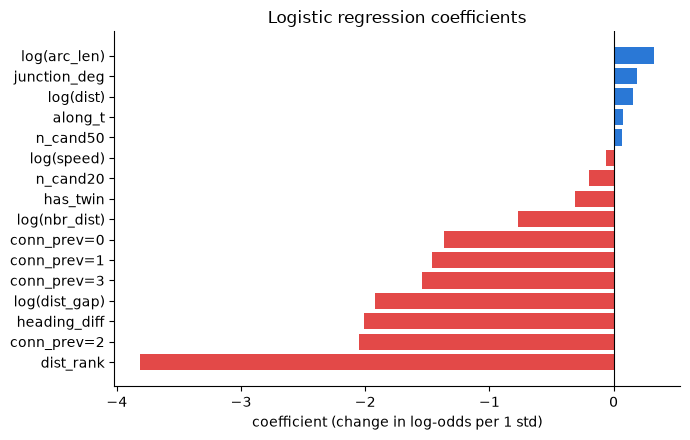

In [5]:
lr = final_model[-1]
names = ([f"log({f})" for f in LOG_FEATURES if f in FEATURES]
         + [f for f in FEATURES if f not in LOG_FEATURES + CAT_FEATURES]
         + [f"conn_prev={k}" for k in range(4)])
coef = pd.Series(lr.coef_[0], index=names).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(coef.index, coef.values, color=[RED if v < 0 else BLUE for v in coef.values])
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("coefficient (change in log-odds per 1 std)")
ax.set_title("Logistic regression coefficients"); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / NAME / "fig_coefficients.png", dpi=150); plt.show()

## Save results

Writes `results/<model>/results.json` (config, CV mean/std, student_test metrics), the per-fold table, per-trip student_test table, out-of-fold probabilities (used by the comparison and HMM notebooks) and the fitted model.

In [6]:
summary = save_results(NAME, FAMILY, CONFIG, cv, test_res, model=final_model if SAVE_MODEL else None,
                       oof=oof, p_test=p_test)
print(json.dumps({k: summary[k] for k in ["name", "family", "config"]}, indent=1))
print("saved to", OUT_DIR / NAME)

{
 "name": "logistic_regression",
 "family": "Linear / probabilistic",
 "config": {
  "C": 1.0,
  "penalty": "l2",
  "solver": "lbfgs",
  "max_iter": 500,
  "preprocessing": "log1p+standardise, one-hot conn_prev",
  "train_frac": 0.4
 }
}
saved to /home/av8/Documents/ML/Hackathon/results/logistic_regression
